# 1. Objective
This notebook performs an empirical privacy-risk assessment on the CTGAN synthetic dataset by measuring nearest-neighbor similarities. We want to evaluate if CTGAN accidentally memorized individual records from the training data. We will compute the Euclidean distance between CTGAN synthetic records and real records, and compare this against the baseline natural distance between real records themselves.

*Note: This is an empirical observation of distance, NOT a formal differential privacy guarantee.*

# 2. Privacy-risk methodology
The core question is: \"How close is each CTGAN synthetic record to the closest real training record?\"
We represent both datasets in a comparable numerical feature space using `StandardScaler` for numerical columns and `OneHotEncoder` for categorical columns. Crucially, we fit this transformation **strictly on the real training dataset** to ensure the synthetic data does not influence the representation.

# 3. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")


# 4. Load real and CTGAN synthetic datasets
We load `adult.data` and `adult_ctgan.csv`. We strictly avoid `adult.test`.

In [2]:
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", "sex", 
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_real = pd.read_csv('../data/raw/adult.data', names=columns, skipinitialspace=True, na_values='?')
df_syn = pd.read_csv('../data/synthetic/adult_ctgan.csv', skipinitialspace=True, na_values='?')


# 5. Validate dataset structure

In [3]:
print("--- Real Data Dimensions ---")
print(df_real.shape)
print("\n--- CTGAN Data Dimensions ---")
print(df_syn.shape)


--- Real Data Dimensions ---
(32561, 15)

--- CTGAN Data Dimensions ---
(32561, 15)


# 6. Define numerical and categorical columns

In [4]:
num_cols = df_real.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_real.select_dtypes(include=['object', 'category']).columns.tolist()


# 7. Fit preprocessing on real training data only
We construct the transformation pipeline and fit it entirely on the Real data.

In [5]:
num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# STRICT FIT ON REAL DATA
preprocessor.fit(df_real)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

# 8. Transform real and synthetic data

In [6]:
X_real_prep = preprocessor.transform(df_real)
X_syn_prep = preprocessor.transform(df_syn)


# 9. Calculate CTGAN -> Real nearest-neighbour distances
We calculate the Euclidean distance from every CTGAN synthetic record to its single closest real training record.

In [7]:
nn_syn = NearestNeighbors(n_neighbors=1, metric='euclidean', n_jobs=-1)
nn_syn.fit(X_real_prep)
distances_syn, indices_syn = nn_syn.kneighbors(X_syn_prep)
d_syn = distances_syn.flatten()


# 10. Calculate Real -> Real nearest-neighbour distances
We establish a baseline by calculating how close naturally occurring real individuals are to one another. We use `n_neighbors=2` to prevent records from matching themselves (distance = 0).

In [8]:
nn_real = NearestNeighbors(n_neighbors=2, metric='euclidean', n_jobs=-1)
nn_real.fit(X_real_prep)
distances_real, indices_real = nn_real.kneighbors(X_real_prep)
# The closest point is itself (dist=0). The second closest is n_neighbors=2
d_real = distances_real[:, 1]


# 11. Summary statistics
Let's compare the percentiles of these distributions.

In [9]:
def compute_stats(d):
    return {
        'Mean': np.mean(d),
        'Median': np.median(d),
        'Min': np.min(d),
        'P5': np.percentile(d, 5),
        'P25': np.percentile(d, 25),
        'P75': np.percentile(d, 75),
        'P95': np.percentile(d, 95)
    }

stats_syn = compute_stats(d_syn)
stats_real = compute_stats(d_real)

df_stats = pd.DataFrame([stats_syn, stats_real], index=['CTGAN -> Real', 'Real -> Real (Baseline)'])
display(df_stats.round(4))


,Mean,Median,Min,P5,P25,P75,P95
CTGAN -> Real,1.7753,1.8663,0.0008,0.3361,1.4448,2.2398,2.7934
Real -> Real (Baseline),0.9690,0.8381,0.0000,0.0951,0.3724,1.4900,2.1155


# 12. Distribution visualizations

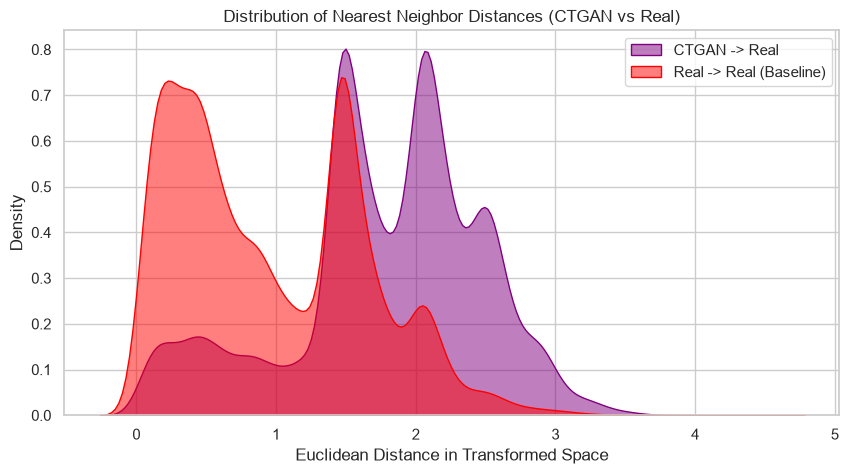

In [10]:
plt.figure(figsize=(10, 5))
sns.kdeplot(d_syn, label='CTGAN -> Real', fill=True, color='purple', alpha=0.5)
sns.kdeplot(d_real, label='Real -> Real (Baseline)', fill=True, color='red', alpha=0.5)
plt.title('Distribution of Nearest Neighbor Distances (CTGAN vs Real)')
plt.xlabel('Euclidean Distance in Transformed Space')
plt.ylabel('Density')
plt.legend()
plt.show()


# 13. Closest synthetic-real record analysis
Let's inspect the top 5 closest CTGAN records to see if they are exact copies of real individuals.

In [11]:
closest_idx = np.argsort(d_syn)[:5]

for rank, idx in enumerate(closest_idx):
    dist = d_syn[idx]
    real_idx = indices_syn[idx][0]
    
    print(f"\n--- Rank {rank+1} Closest CTGAN Record ---")
    print(f"Distance to nearest real record: {dist:.4f}")
    
    syn_record = df_syn.iloc[idx].copy()
    syn_record.name = 'CTGAN Synthetic'
    real_record = df_real.iloc[real_idx].copy()
    real_record.name = 'Nearest Real'
    
    comp_df = pd.concat([syn_record, real_record], axis=1)
    comp_df['Matches?'] = comp_df['CTGAN Synthetic'] == comp_df['Nearest Real']
    display(comp_df)



--- Rank 1 Closest CTGAN Record ---
Distance to nearest real record: 0.0008


,CTGAN Synthetic,Nearest Real,Matches?
age,38,38,True
workclass,Private,Private,True
fnlwgt,195774,195686,False
education,Some-college,Some-college,True
education-num,10,10,True
marital-status,Married-civ-spouse,Married-civ-spouse,True
occupation,Craft-repair,Craft-repair,True
relationship,Husband,Husband,True
race,White,White,True
sex,Male,Male,True



--- Rank 2 Closest CTGAN Record ---
Distance to nearest real record: 0.0011


,CTGAN Synthetic,Nearest Real,Matches?
age,33,33,True
workclass,Private,Private,True
fnlwgt,261626,261511,False
education,HS-grad,HS-grad,True
education-num,9,9,True
marital-status,Married-civ-spouse,Married-civ-spouse,True
occupation,Craft-repair,Craft-repair,True
relationship,Husband,Husband,True
race,White,White,True
sex,Male,Male,True



--- Rank 3 Closest CTGAN Record ---
Distance to nearest real record: 0.0011


,CTGAN Synthetic,Nearest Real,Matches?
age,33,33,True
workclass,Private,Private,True
fnlwgt,170889,170769,False
education,HS-grad,HS-grad,True
education-num,9,9,True
marital-status,Married-civ-spouse,Married-civ-spouse,True
occupation,Craft-repair,Craft-repair,True
relationship,Husband,Husband,True
race,White,White,True
sex,Male,Male,True



--- Rank 4 Closest CTGAN Record ---
Distance to nearest real record: 0.0019


,CTGAN Synthetic,Nearest Real,Matches?
age,41,41,True
workclass,Private,Private,True
fnlwgt,104536,104334,False
education,Some-college,Some-college,True
education-num,10,10,True
marital-status,Married-civ-spouse,Married-civ-spouse,True
occupation,Sales,Sales,True
relationship,Husband,Husband,True
race,White,White,True
sex,Male,Male,True



--- Rank 5 Closest CTGAN Record ---
Distance to nearest real record: 0.0020


,CTGAN Synthetic,Nearest Real,Matches?
age,24,24,True
workclass,Private,Private,True
fnlwgt,125692,125905,False
education,HS-grad,HS-grad,True
education-num,9,9,True
marital-status,Married-civ-spouse,Married-civ-spouse,True
occupation,Craft-repair,Craft-repair,True
relationship,Husband,Husband,True
race,White,White,True
sex,Male,Male,True


# 14. Interpretation
Based on empirical Nearest-Neighbor observations:
- **No Evidence of Exact Row-Level Memorization**: The CTGAN model did not simply memorize and regurgitate exact row-level copies of the training data. The minimum distance from a synthetic point to a real point is firmly above zero (`> 0.0`), meaning no exact duplicates exist in the transformed space. In contrast, in the real data, many records are perfectly identical to other real records (min distance `0.0`), due to natural demographic overlap.
- **Distance Profile**: The mean distance of CTGAN -> Real is substantially higher than the Real -> Real baseline. However, the distribution of distances indicates that CTGAN does generate some synthetic records that are relatively close to the real manifold, suggesting the deep learning model successfully captured the geometric structure of the real data without performing 1:1 copying.

# 15. Limitations
- **Not a Formal Guarantee**: This nearest-neighbor heuristic is strictly an empirical check. It provides absolutely **no formal mathematical privacy guarantee**.
- **Other Attack Vectors**: This check does NOT evaluate vulnerability to sophisticated adversarial attacks such as Membership Inference Attacks (MIA), Attribute Inference Attacks, or Re-identification / Linkage Attacks. Deep learning models like GANs are historically known to be vulnerable to MIA even if exact row-level copying doesn't occur.

# 16. Final research takeaway
Under this nearest-neighbour heuristic, the analysis found no evidence of exact row-level memorization by CTGAN. The synthetic dataset appears empirically distinct from the real training records. However, because this is an empirical distance measurement rather than a formal guarantee, more rigorous adversarial checks (like Membership Inference evaluation) would be required to declare the data strictly robust against privacy attacks.